# Practical 13 — Stock Price Time-Series Analysis

Create stock-price history, plot closing prices and moving averages, inspect seasonality/correlation and produce an ARIMA forecast.

**Run the cells from top to bottom.** The dataset is generated inside this notebook before the practical begins.

## 1. Install / import requirements

If a package is missing, run `!pip install pandas numpy matplotlib seaborn scikit-learn statsmodels openpyxl requests xgboost` in a notebook cell. Most environments already have the common packages.

In [1]:
from pathlib import Path
Path('data').mkdir(exist_ok=True)


## 2. Create the required dataset

This is the relevant part of `make_data.py`, placed here so the notebook is self-contained.

In [2]:
# Create synthetic business-day stock prices for time-series analysis.
import numpy as np, pandas as pd
rng=np.random.default_rng(42); n=750
close=100+np.cumsum(rng.normal(.1,1.5,n))
stocks=pd.DataFrame({"Date":pd.bdate_range("2022-01-03",periods=n),
 "Close":close.round(2),"Volume":rng.integers(1_000_000,5_000_000,n)})
stocks.to_csv("data/Stock_Prices.csv",index=False)
print("Created data/Stock_Prices.csv")


Created data/Stock_Prices.csv


## 3. Practical implementation

The following cells perform the analysis and show the output.

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 750 entries, 2022-01-03 to 2024-11-15
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   750 non-null    float64
 1   Volume  750 non-null    int64  
dtypes: float64(1), int64(1)
memory usage: 17.6 KB
             Close   Volume
Date                       
2022-01-03  100.56  2164533
2022-01-04   99.10  2017053
2022-01-05  100.32  1993897
2022-01-06  101.83  4675174
2022-01-07   99.01  3227741
None


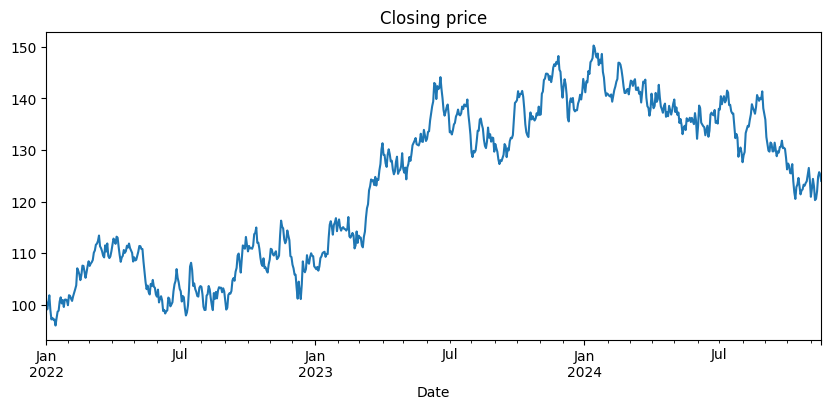

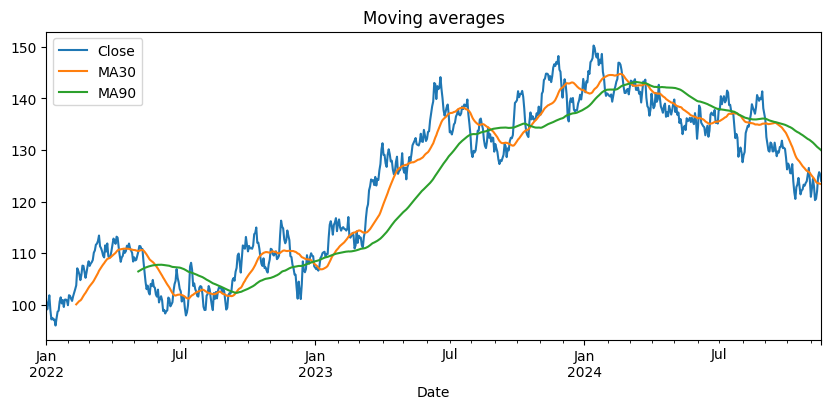

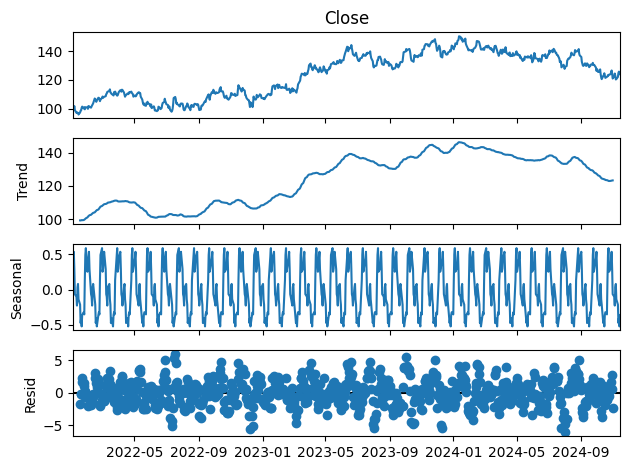

Correlation Close vs Volume: 0.02


c:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency B will be used.
  self._init_dates(dates, freq)
c:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency B will be used.
  self._init_dates(dates, freq)
c:\ProgramData\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency B will be used.
  self._init_dates(dates, freq)


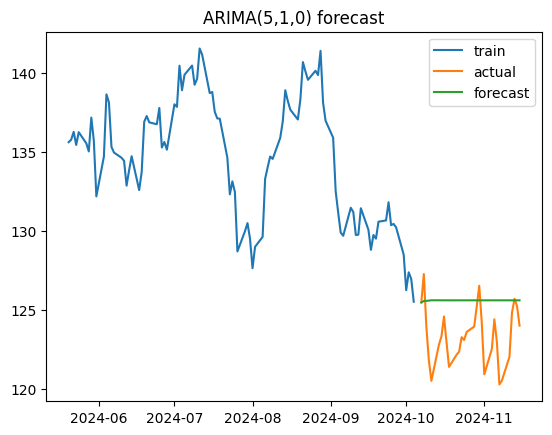

In [3]:
import pandas as pd, matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import seasonal_decompose

df = pd.read_csv("data/Stock_Prices.csv", parse_dates=["Date"], index_col="Date")   # date -> datetime index
print(df.head(), df.info(), sep="\n")

df.Close.plot(title="Closing price", figsize=(10, 4)); plt.show()

df["MA30"], df["MA90"] = df.Close.rolling(30).mean(), df.Close.rolling(90).mean()    # moving averages
df[["Close", "MA30", "MA90"]].plot(title="Moving averages", figsize=(10, 4)); plt.show()

seasonal_decompose(df.Close, model="additive", period=21).plot(); plt.show()          # ~monthly seasonality

print("Correlation Close vs Volume:", round(df.Close.corr(df.Volume), 3))             # correlation

train, test = df.Close[:-30], df.Close[-30:]                                          # ARIMA forecast
fc = ARIMA(train, order=(5, 1, 0)).fit().forecast(30)
plt.plot(train[-100:], label="train"); plt.plot(test, label="actual"); plt.plot(test.index, fc, label="forecast")
plt.legend(); plt.title("ARIMA(5,1,0) forecast"); plt.show()